<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp11_Credit_Score_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 11: Credit Score Classification
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program for the task of Credit Score Classification.

## Background
Banks classify customers as **Poor / Standard / Good** credit risks from financial behaviour (income, debt, payment delays, credit history ...). This is a **multi-class classification** problem on *mixed* data (numeric + categorical, with missing values), so a proper `Pipeline` with imputation, scaling and one-hot encoding is used. Because classes are imbalanced, we judge models by **macro-F1** in addition to accuracy.



## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
We generate a realistic dataset of **3,000 customers** with 17 attributes, including some missing values and categorical fields (similar in structure to the popular Kaggle *Credit Score Classification* data). The credit score label comes from a hidden risk score built from payment delays, debt, income, history length etc. plus noise, so real patterns exist for the models to learn. Saved as `credit_score.csv`.

In [2]:
rng = np.random.RandomState(42)
n = 3000
zs = lambda v: (v - v.mean()) / v.std()

age = rng.randint(18, 70, n)
income = np.clip(rng.lognormal(10.8, 0.55, n), 10000, 200000).round(0)
interest = np.clip(rng.normal(14, 6, n), 1, 34).round(0)
delay_days = np.clip(rng.normal(15, 11, n) + 0.5 * (interest - 14), 0, 60).round(0)
delayed_pay = np.clip(rng.poisson(np.maximum(delay_days / 3, 0.2)), 0, 25)
debt = np.clip(rng.lognormal(7.2, 0.8, n), 20, 5000).round(2)
util = np.clip(rng.normal(32, 6, n), 20, 50).round(2)
history = rng.randint(12, 400, n)
pay_min = rng.choice(["Yes", "No"], n, p=[0.6, 0.4])

risk = (-0.9 * zs(delay_days) - 0.6 * zs(delayed_pay) - 0.7 * zs(np.log(debt)) + 0.5 * zs(history)
        + 0.35 * zs(np.log(income)) - 0.5 * zs(interest) - 0.4 * zs(util)
        - 0.4 * zs((pay_min == "No").astype(float)) + rng.normal(0, 0.6, n))
q30, q80 = np.quantile(risk, [0.30, 0.80])
credit_score = np.where(risk < q30, "Poor", np.where(risk > q80, "Good", "Standard"))

mix_raw = -zs(np.log(debt)) - zs(util) + rng.normal(0, 1.2, n)
q1, q2 = np.quantile(mix_raw, [1 / 3, 2 / 3])
credit_mix = np.where(mix_raw < q1, "Bad", np.where(mix_raw < q2, "Standard", "Good"))

df_gen = pd.DataFrame({
    "Customer_ID": [f"CUS{100000 + i}" for i in range(n)],
    "Age": age,
    "Occupation": rng.choice(["Engineer", "Teacher", "Doctor", "Manager", "Lawyer", "Mechanic", "Accountant", "Developer"], n),
    "Annual_Income": income,
    "Monthly_Inhand_Salary": (income / 12 * 0.85).round(2),
    "Num_Bank_Accounts": rng.randint(1, 10, n),
    "Num_Credit_Card": rng.randint(1, 10, n),
    "Interest_Rate": interest,
    "Num_of_Loan": rng.randint(0, 9, n),
    "Delay_from_due_date": delay_days,
    "Num_of_Delayed_Payment": delayed_pay.astype(float),
    "Credit_Mix": credit_mix,
    "Outstanding_Debt": debt,
    "Credit_Utilization_Ratio": util,
    "Credit_History_Age": history.astype(float),
    "Payment_of_Min_Amount": pay_min,
    "Total_EMI_per_month": np.clip(rng.lognormal(4.2, 0.9, n), 0, 1500).round(2),
    "Payment_Behaviour": rng.choice(["Low_spent_Small_payments", "High_spent_Large_payments", "Low_spent_Large_payments",
                                      "High_spent_Small_payments", "Medium_spent_Medium_payments"], n),
    "Monthly_Balance": np.clip(rng.normal(350, 150, n), 10, 1000).round(2),
    "Credit_Score": credit_score,
})
# inject realistic missing values
for col, frac in {"Num_of_Delayed_Payment": 0.07, "Credit_History_Age": 0.09, "Monthly_Balance": 0.02, "Occupation": 0.04}.items():
    df_gen.loc[rng.rand(n) < frac, col] = np.nan

df_gen.to_csv("credit_score.csv", index=False)
print("Saved credit_score.csv", df_gen.shape)

Saved credit_score.csv (3000, 20)


## Step 2: Data Loading

In [3]:
df = pd.read_csv("credit_score.csv")
df.head()

,Customer_ID,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Payment_Behaviour,Monthly_Balance,Credit_Score
0,CUS100000,56,Mechanic,77704.0,5504.03,9,9,18.0,5,30.0,12.0,Good,883.23,28.53,349.0,Yes,164.24,Medium_spent_Medium_payments,252.49,Standard
1,CUS100001,69,Mechanic,31335.0,2219.56,8,3,22.0,1,28.0,NaN,Bad,3996.29,35.55,NaN,No,42.43,Medium_spent_Medium_payments,227.74,Poor
2,CUS100002,46,Doctor,95564.0,6769.12,1,2,23.0,2,19.0,4.0,Bad,4120.00,36.11,243.0,Yes,96.54,High_spent_Small_payments,365.21,Poor
3,CUS100003,32,Accountant,45387.0,3214.91,3,1,17.0,8,6.0,4.0,Bad,5000.00,30.96,161.0,Yes,61.63,Low_spent_Large_payments,245.50,Standard
4,CUS100004,60,Engineer,79916.0,5660.72,9,1,8.0,8,14.0,NaN,Good,1834.64,29.86,201.0,Yes,29.56,High_spent_Large_payments,354.81,Good


## Step 3: Data Preprocessing
1. Drop identifier columns (no predictive value).  2. Encode the target.  3. Stratified train/test split.  4. Build a `ColumnTransformer`: numeric -> median imputation + scaling; categorical -> most-frequent imputation + one-hot encoding. All steps are fitted on training data only (inside the pipeline), so there is no leakage.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

df = df.drop(columns="Customer_ID")
target = "Credit_Score"
le = LabelEncoder()
y = le.fit_transform(df[target])
X = df.drop(columns=target)
print("Classes:", dict(zip(le.classes_, le.transform(le.classes_))))

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
print("\nTrain:", X_train.shape, "Test:", X_test.shape)

Classes: {'Good': np.int64(0), 'Poor': np.int64(1), 'Standard': np.int64(2)}
Numeric: ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Total_EMI_per_month', 'Monthly_Balance']
Categorical: ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']

Train: (2400, 18) Test: (600, 18)


## Step 4: Exploratory Data Analysis (EDA)

In [5]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nClass distribution:\n", df[target].value_counts(normalize=True).round(3))
print(df.describe().T.round(2))

Shape: (3000, 19)

Missing values:
 Occupation                109
Num_of_Delayed_Payment    204
Credit_History_Age        242
Monthly_Balance            57
dtype: int64

Class distribution:
 Credit_Score
Standard    0.5
Poor        0.3
Good        0.2
Name: proportion, dtype: float64
                           count      mean       std       min       25%  \
Age                       3000.0     43.56     14.94     18.00     31.00   
Annual_Income             3000.0  56310.89  31984.16  10000.00  33608.25   
Monthly_Inhand_Salary     3000.0   3988.69   2265.54    708.33   2380.58   
Num_Bank_Accounts         3000.0      4.91      2.59      1.00      3.00   
Num_Credit_Card           3000.0      5.02      2.59      1.00      3.00   
Interest_Rate             3000.0     13.89      6.04      1.00     10.00   
Num_of_Loan               3000.0      4.06      2.60      0.00      2.00   
Delay_from_due_date       3000.0     15.33     10.48      0.00      7.00   
Num_of_Delayed_Payment    2796.

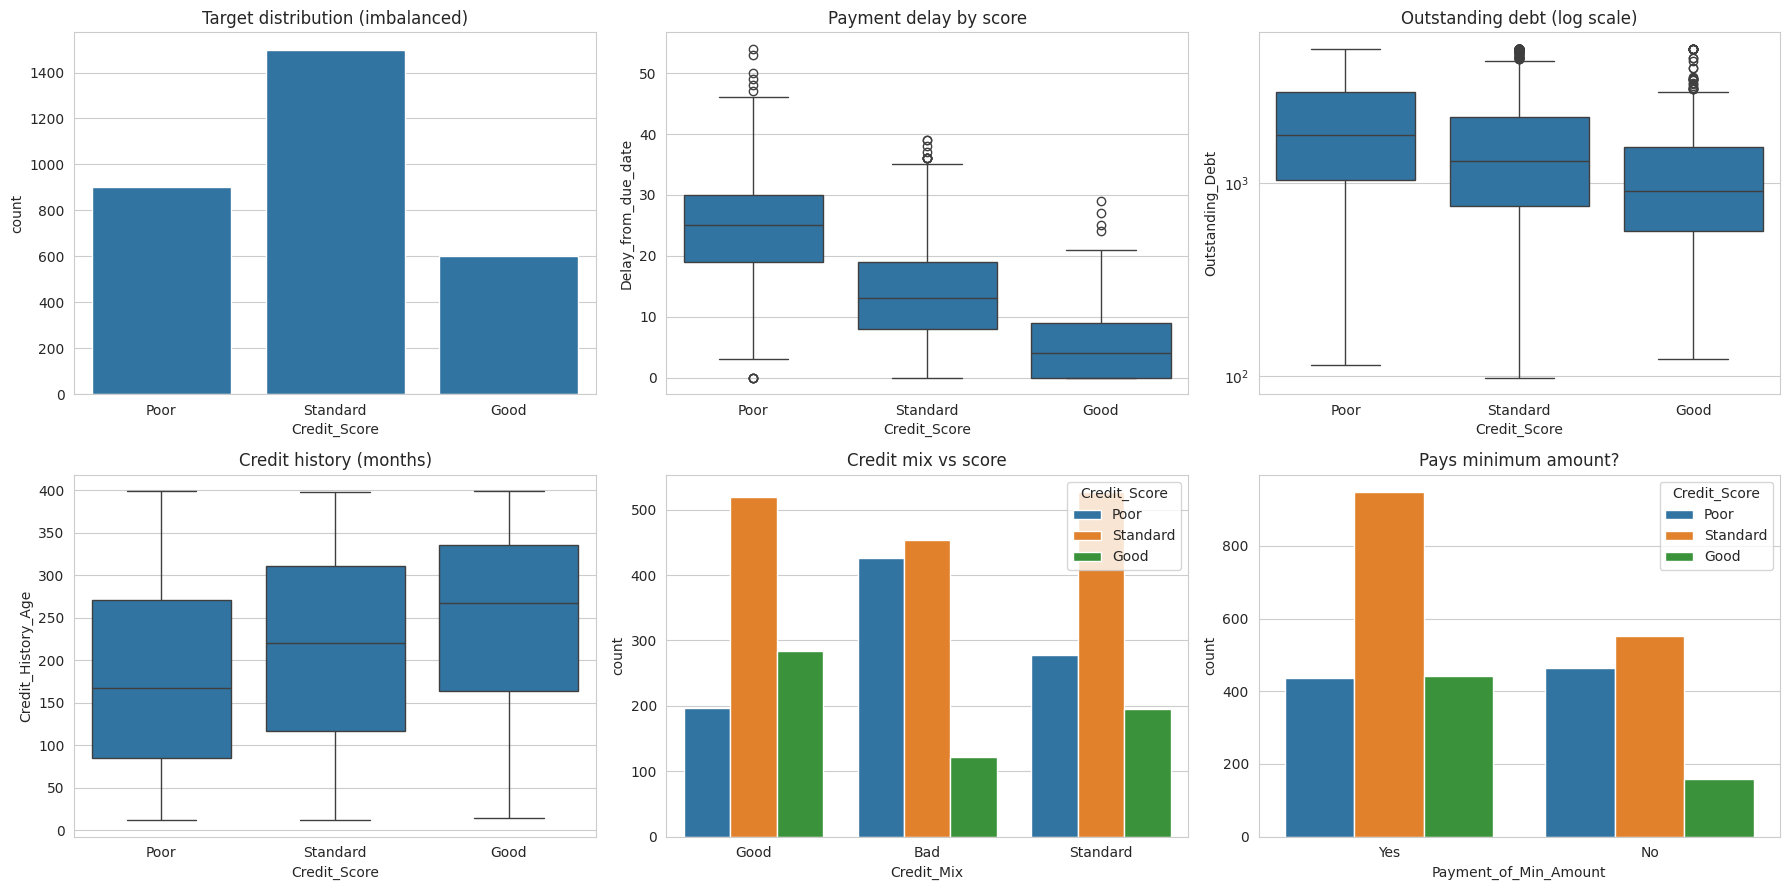

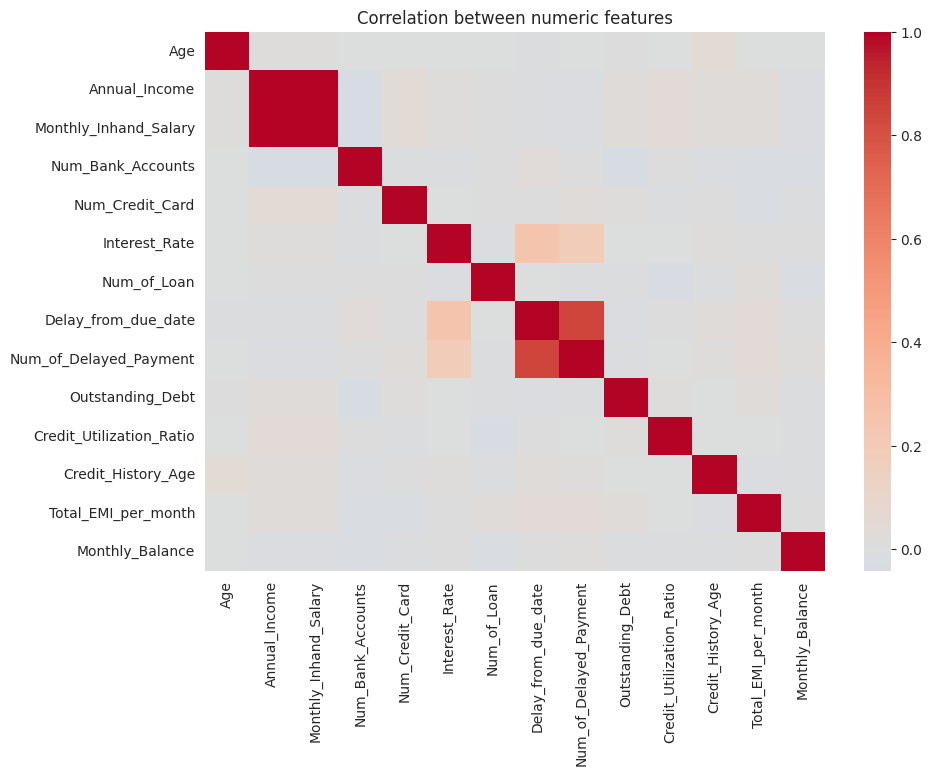

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
order = ["Poor", "Standard", "Good"]
sns.countplot(data=df, x=target, order=order, ax=axes[0, 0]); axes[0, 0].set_title("Target distribution (imbalanced)")
sns.boxplot(data=df, x=target, y="Delay_from_due_date", order=order, ax=axes[0, 1]); axes[0, 1].set_title("Payment delay by score")
sns.boxplot(data=df, x=target, y="Outstanding_Debt", order=order, ax=axes[0, 2]); axes[0, 2].set_yscale("log"); axes[0, 2].set_title("Outstanding debt (log scale)")
sns.boxplot(data=df, x=target, y="Credit_History_Age", order=order, ax=axes[1, 0]); axes[1, 0].set_title("Credit history (months)")
sns.countplot(data=df, x="Credit_Mix", hue=target, hue_order=order, ax=axes[1, 1]); axes[1, 1].set_title("Credit mix vs score")
sns.countplot(data=df, x="Payment_of_Min_Amount", hue=target, hue_order=order, ax=axes[1, 2]); axes[1, 2].set_title("Pays minimum amount?")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation between numeric features"); plt.show()

## Step 5: Model Training
We compare three classifiers inside full pipelines using **5-fold stratified cross-validation** (macro-F1), then train the best one on the full training set.

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, random_state=42),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, clf in candidates.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="f1_macro")
    cv_results[name] = scores
    print(f"{name:<22} macro-F1 = {scores.mean():.4f} (+/- {scores.std():.4f})")

best_name = max(cv_results, key=lambda k: cv_results[k].mean())
print("\nBest model by CV:", best_name)
best_model = Pipeline([("prep", preprocessor), ("clf", candidates[best_name])]).fit(X_train, y_train)

Logistic Regression    macro-F1 = 0.8090 (+/- 0.0127)
Random Forest          macro-F1 = 0.7587 (+/- 0.0179)
Gradient Boosting      macro-F1 = 0.7956 (+/- 0.0123)

Best model by CV: Logistic Regression


## Step 6: Model Evaluation
Final evaluation on the untouched test set: accuracy, per-class precision / recall / F1, confusion matrix and feature importance.

Test accuracy: 0.8433
              precision    recall  f1-score   support

        Good       0.81      0.72      0.77       120
        Poor       0.88      0.89      0.89       180
    Standard       0.83      0.86      0.85       300

    accuracy                           0.84       600
   macro avg       0.84      0.83      0.83       600
weighted avg       0.84      0.84      0.84       600



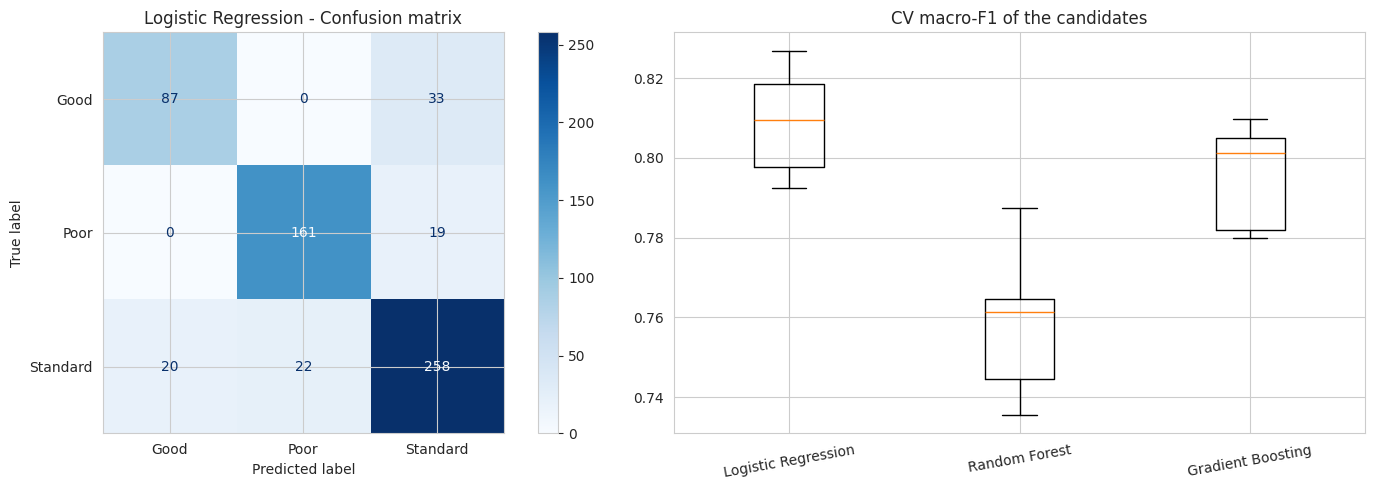

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = best_model.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=le.classes_))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_).plot(ax=axes[0], cmap="Blues")
axes[0].set_title(f"{best_name} - Confusion matrix")
axes[1].boxplot(list(cv_results.values())); axes[1].set_xticklabels(list(cv_results.keys()), rotation=10); axes[1].set_title("CV macro-F1 of the candidates")
plt.tight_layout(); plt.show()

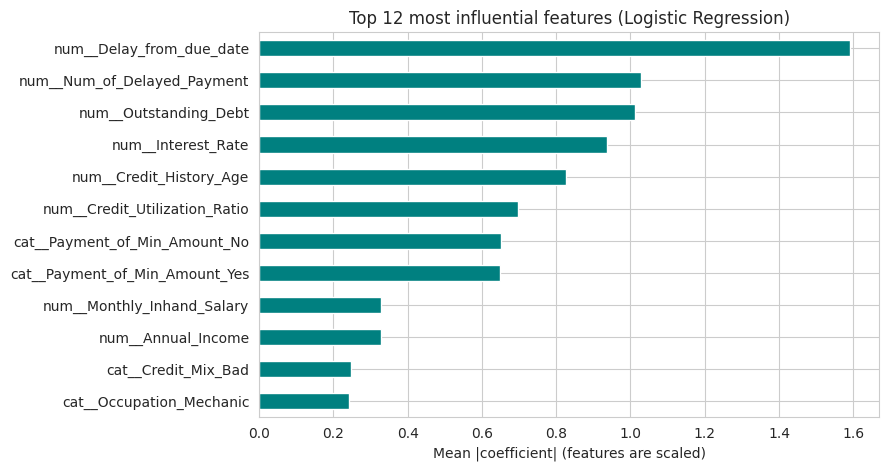

In [9]:
clf = best_model.named_steps["clf"]
names = best_model.named_steps["prep"].get_feature_names_out()
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=names); label = "Importance"
else:                                     # linear model: average absolute coefficient over the classes
    imp = pd.Series(np.abs(clf.coef_).mean(axis=0), index=names); label = "Mean |coefficient| (features are scaled)"
imp = imp.sort_values(ascending=False).head(12)
imp.iloc[::-1].plot(kind="barh", color="teal", figsize=(8, 5))
plt.title(f"Top 12 most influential features ({best_name})"); plt.xlabel(label); plt.show()

## Step 7: Prediction on New Data
Score a brand-new customer (raw values - the pipeline handles imputation, scaling and encoding).

In [10]:
new_customer = pd.DataFrame([{
    "Age": 34, "Occupation": "Engineer", "Annual_Income": 72000, "Monthly_Inhand_Salary": 5100,
    "Num_Bank_Accounts": 3, "Num_Credit_Card": 4, "Interest_Rate": 8, "Num_of_Loan": 1,
    "Delay_from_due_date": 3, "Num_of_Delayed_Payment": 1, "Credit_Mix": "Good", "Outstanding_Debt": 400.0,
    "Credit_Utilization_Ratio": 28.0, "Credit_History_Age": 240, "Payment_of_Min_Amount": "Yes",
    "Total_EMI_per_month": 60.0, "Payment_Behaviour": "Low_spent_Large_payments", "Monthly_Balance": 400.0}])
proba = best_model.predict_proba(new_customer)[0]
print("Predicted credit score:", le.inverse_transform(best_model.predict(new_customer))[0])
print("Probabilities:", dict(zip(le.classes_, proba.round(3))))

Predicted credit score: Good
Probabilities: {'Good': np.float64(0.995), 'Poor': np.float64(0.0), 'Standard': np.float64(0.005)}


## Conclusion
All three models find strong signal in payment delay, outstanding debt, credit history and interest rate. Logistic Regression scored best in cross-validation here (about 0.81 macro-F1, ~84% test accuracy) with Gradient Boosting close behind and Random Forest last - plausible because this synthetic risk score is a smooth, roughly linear combination of the features; on real, messier data tree ensembles often win, so always compare. The smallest class (**Good**) is the hardest to recall. Wrapping preprocessing in a `Pipeline` made the workflow leak-free and made scoring new customers a one-liner. To improve further: handle class imbalance (`class_weight`), tune hyper-parameters and add more behavioural features.